Dataset PBL pada file `burnout_dataset1.csv` berisi 50.000 observasi profil karyawan dan gaya hidup. Fitur numerik yang digunakan adalah Age, Work_Hours_Per_Week, Sleep_Hours, Job_Satisfaction, Work_Life_Balance, Anxiety_Score, Depression_Score, Physical_Activity_Hours, dan Screen_Time_Hours. Fitur kategori yang digunakan adalah Gender, Remote_Work, Stress_Level, Sleep_Quality, dan Chronic_Stress. Target `Burnout_Score` adalah skor tingkat kejenuhan kerja (burnout) dalam rentang 0 hingga 100.

Model multiple linear regression menggunakan fitur-fitur tersebut. Data dibagi menjadi 80% data latih dan 20% data uji. Nilai kosong ditangani melalui imputasi di dalam pipeline prapemrosesan: fitur numerik diimputasi dengan median lalu distandardisasi, sedangkan fitur kategori diimputasi dengan modus lalu dikodekan dengan one-hot encoding.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
dataset_path = Path('burnout_dataset1.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'Dataset PBL' / 'burnout_dataset1.csv'

data = pd.read_csv(dataset_path)
print('Ukuran dataset:', data.shape)
print('Jumlah nilai kosong pada fitur terpilih:')
fitur_terpilih = [
    'Age', 'Work_Hours_Per_Week', 'Sleep_Hours', 'Job_Satisfaction',
    'Work_Life_Balance', 'Anxiety_Score', 'Depression_Score',
    'Physical_Activity_Hours', 'Screen_Time_Hours',
    'Gender', 'Remote_Work', 'Stress_Level', 'Sleep_Quality', 'Chronic_Stress',
    'Burnout_Score'
]
print(data[fitur_terpilih].isna().sum())
data[fitur_terpilih].head()

Ukuran dataset: (50000, 40)
Jumlah nilai kosong pada fitur terpilih:
Age                         250
Work_Hours_Per_Week           0
Sleep_Hours                 950
Job_Satisfaction            500
Work_Life_Balance           650
Anxiety_Score               800
Depression_Score            850
Physical_Activity_Hours    1100
Screen_Time_Hours           850
Gender                        0
Remote_Work                   0
Stress_Level                  0
Sleep_Quality                 0
Chronic_Stress                0
Burnout_Score                 0
dtype: int64


,Age,Work_Hours_Per_Week,Sleep_Hours,Job_Satisfaction,Work_Life_Balance,Anxiety_Score,Depression_Score,Physical_Activity_Hours,Screen_Time_Hours,Gender,Remote_Work,Stress_Level,Sleep_Quality,Chronic_Stress,Burnout_Score
0,58.0,67,4.6,3.0,7.0,74.0,75.0,8.9,9.1,Male,Hybrid,High,Poor,Yes,82
1,24.0,44,4.7,5.0,8.0,58.0,80.0,0.8,12.0,Female,Hybrid,Moderate,Poor,No,64
2,59.0,60,6.3,8.0,7.0,54.0,55.0,6.9,10.2,Male,No,Moderate,Average,No,50
3,65.0,25,7.1,2.0,9.0,12.0,11.0,7.6,3.3,Other,Yes,Low,Good,No,16
4,64.0,52,9.1,1.0,4.0,25.0,48.0,6.1,6.5,Other,No,Low,Excellent,No,26


In [3]:
data[fitur_terpilih].describe(include='all')

,Age,Work_Hours_Per_Week,Sleep_Hours,Job_Satisfaction,Work_Life_Balance,Anxiety_Score,Depression_Score,Physical_Activity_Hours,Screen_Time_Hours,Gender,Remote_Work,Stress_Level,Sleep_Quality,Chronic_Stress,Burnout_Score
count,49750.000000,50000.000000,49050.000000,49500.000000,49350.000000,49200.000000,49150.000000,48900.000000,49150.000000,50000,50000,50000,50000,50000,50000.00000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,4,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Female,No,Low,Good,No,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16810,16693,21587,16852,43262,NaN
mean,41.448181,44.946160,6.997445,5.499051,5.504397,40.449045,40.601160,4.988035,7.991274,NaN,NaN,NaN,NaN,NaN,40.20188
std,13.871634,14.729024,1.728766,2.866621,2.867492,26.004291,26.308933,2.870014,3.472498,NaN,NaN,NaN,NaN,NaN,26.22312
min,18.000000,20.000000,4.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,NaN,NaN,NaN,NaN,NaN,0.00000
25%,29.000000,32.000000,5.500000,3.000000,3.000000,19.000000,19.000000,2.500000,5.000000,NaN,NaN,NaN,NaN,NaN,19.00000
50%,41.000000,45.000000,7.000000,6.000000,6.000000,39.000000,39.000000,5.000000,8.000000,NaN,NaN,NaN,NaN,NaN,39.00000
75%,53.000000,58.000000,8.500000,8.000000,8.000000,59.000000,60.000000,7.400000,11.000000,NaN,NaN,NaN,NaN,NaN,59.00000


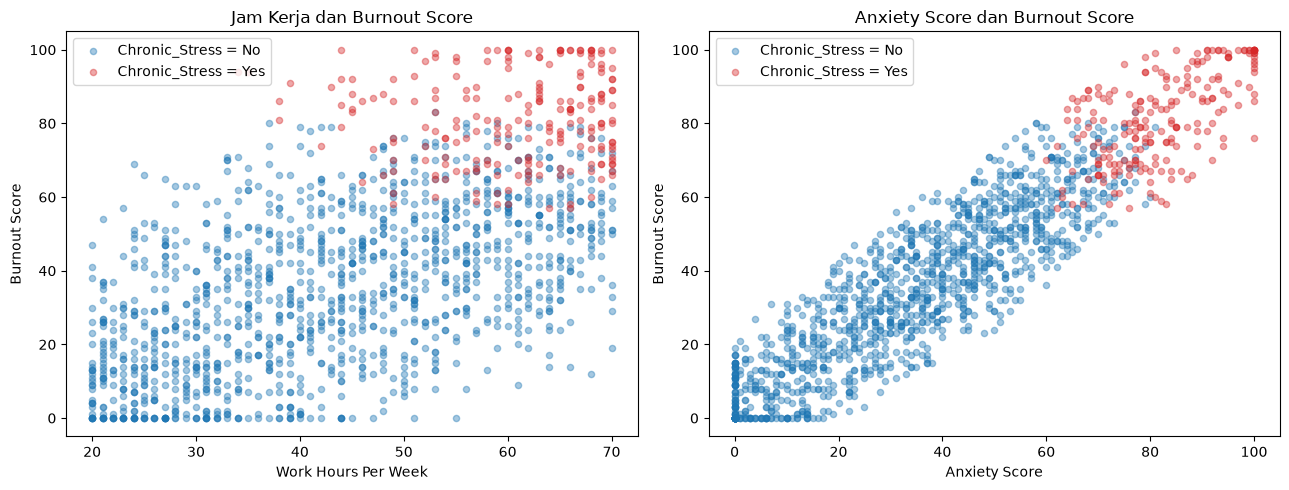

In [4]:
data_plot = data.sample(n=1500, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for status, warna in [('No', 'tab:blue'), ('Yes', 'tab:red')]:
    subset = data_plot[data_plot['Chronic_Stress'] == status]
    axes[0].scatter(subset['Work_Hours_Per_Week'], subset['Burnout_Score'], color=warna,
                    alpha=0.4, s=20, label=f'Chronic_Stress = {status}')
    axes[1].scatter(subset['Anxiety_Score'], subset['Burnout_Score'], color=warna,
                    alpha=0.4, s=20, label=f'Chronic_Stress = {status}')

axes[0].set_xlabel('Work Hours Per Week')
axes[0].set_ylabel('Burnout Score')
axes[0].set_title('Jam Kerja dan Burnout Score')
axes[1].set_xlabel('Anxiety Score')
axes[1].set_ylabel('Burnout Score')
axes[1].set_title('Anxiety Score dan Burnout Score')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
fitur_numerik = [
    'Age', 'Work_Hours_Per_Week', 'Sleep_Hours', 'Job_Satisfaction',
    'Work_Life_Balance', 'Anxiety_Score', 'Depression_Score',
    'Physical_Activity_Hours', 'Screen_Time_Hours'
]
fitur_kategori = [
    'Gender', 'Remote_Work', 'Stress_Level', 'Sleep_Quality', 'Chronic_Stress'
]

X = data[fitur_numerik + fitur_kategori]
y = data['Burnout_Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 40000
Jumlah data uji: 10000


In [6]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numerik', num_pipeline, fitur_numerik),
    ('kategori', cat_pipeline, fitur_kategori)
])

model = Pipeline([
    ('preprocessing', preprocessor),
    ('regresi', LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('regresi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Age','Work_Hours_Per_Week','Sleep_Hours',...,'Stress_Level', 'Sleep_Quality','Chronic_Stress']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerik', ...), ('kategori', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically p

In [7]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

hasil_prediksi = pd.DataFrame({
    'Burnout aktual': y_test,
    'Burnout prediksi': y_pred,
    'Residual': y_test - y_pred
})
hasil_prediksi.head(10)

,Burnout aktual,Burnout prediksi,Residual
33553,52,46.974821,5.025179
9427,42,41.287060,0.712940
199,46,51.727916,-5.727916
12447,58,72.119943,-14.119943
39489,50,47.196733,2.803267
42724,84,74.120265,9.879735
10822,29,44.272415,-15.272415
49498,81,79.868571,1.131429
4144,0,7.800101,-7.800101
36958,25,14.961370,10.038630


In [8]:
r2_train = r2_score(y_train, y_train_pred)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'R-squared data latih: {r2_train:.6f}')
print(f'R-squared data uji: {r2:.6f}')
print(f'MSE data uji: {mse:.4f}')
print(f'MAE data uji: {mae:.4f}')

R-squared data latih: 0.879464
R-squared data uji: 0.879351
MSE data uji: 83.2532
MAE data uji: 7.7316


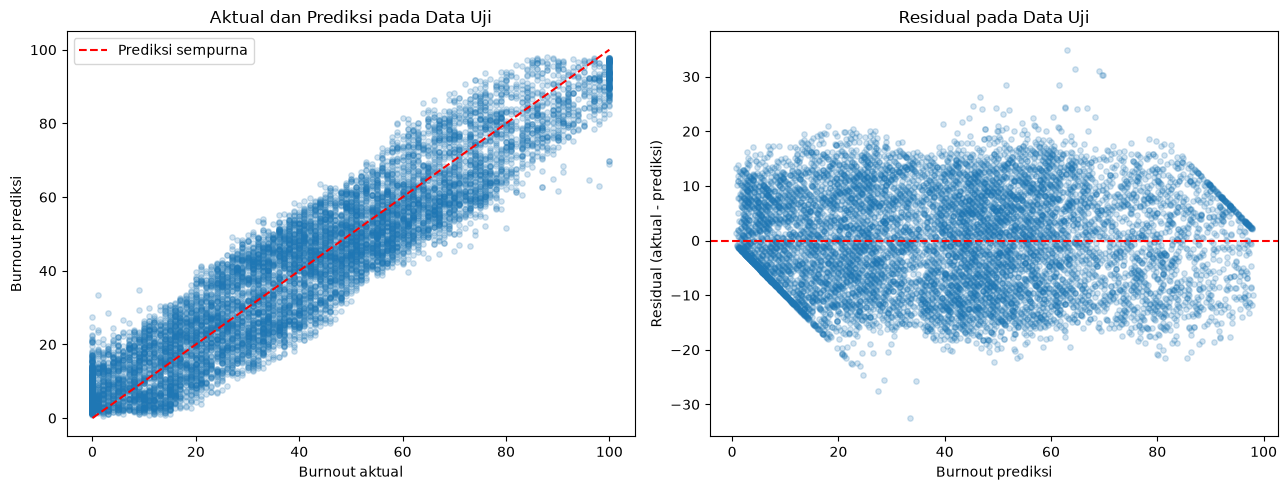

In [9]:
residual = y_test - y_pred
batas = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.2, s=15)
axes[0].plot(batas, batas, color='red', linestyle='--', label='Prediksi sempurna')
axes[0].set_xlabel('Burnout aktual')
axes[0].set_ylabel('Burnout prediksi')
axes[0].set_title('Aktual dan Prediksi pada Data Uji')
axes[0].legend()

axes[1].scatter(y_pred, residual, alpha=0.2, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Burnout prediksi')
axes[1].set_ylabel('Residual (aktual - prediksi)')
axes[1].set_title('Residual pada Data Uji')

plt.tight_layout()
plt.show()

Berdasarkan hasil evaluasi, model multiple linear regression menghasilkan nilai R-squared yang tinggi dan konsisten antara data latih dan data uji. Hal ini menunjukkan bahwa kombinasi fitur numerik dan kategori pada dataset PBL mampu menjelaskan variasi Burnout_Score dengan sangat baik tanpa gejala overfitting, serta nilai MAE dan MSE yang rendah membuktikan kesalahan prediksi rata-rata berada pada rentang yang kecil.